In [1]:
# === Ô GHI LOG (mẫu PL1 bản 2 – chạy được với ipykernel 7): mọi thứ in ra màn hình đồng thời được ghi vào file log ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "00_E0.2_khoang_thieu_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 00:00:32 | INFO | Bắt đầu chạy 00_E0.2_khoang_thieu_Han – người chạy: Han – file log: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/logs/eda_log/2026-11-14_0000_00_E0.2_khoang_thieu_Han.log


# E0.2 – Thiếu ở đâu và kéo dài bao lâu?

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 |
| **Thí nghiệm** | E0.2 – Thiếu ở đâu và kéo dài bao lâu? |
| **Mục đích** | Gom phút thiếu thành các khoảng thiếu liền nhau, xem độ dài và tháng nào thiếu nhiều. |
| **Đọc vào** | `data/raw/individual+household+electric+power+consumption.zip` (đọc thẳng từ zip) |
| **Ghi ra** | `data/eda_data/eda_00_do_dai_khoang_thieu.csv`, `data/eda_data/eda_00_thieu_theo_thang.csv`, `figures/eda_figures/00_thieu_theo_thang.png`, `data/eda_data/eda_E0.2_kho_khan.csv` |
| **Chạy sau** | không cần |

Notebook EDA chỉ đọc và mô tả dữ liệu, không sửa, không xoá, không điền dữ liệu. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_Han.ipynb`.

In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ZIP = ROOT / "data" / "raw" / "individual+household+electric+power+consumption.zip"
TXT = "household_power_consumption.txt"
DIR_DATA, DIR_FIG = ROOT / "data" / "eda_data", ROOT / "figures" / "eda_figures"
DIR_FIG.mkdir(exist_ok=True)

MEAN_COLS = ["Global_active_power", "Global_reactive_power", "Voltage", "Global_intensity"]
SUB_COLS = ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
COLS = MEAN_COLS + SUB_COLS
TARGET = "Global_active_power"
DON_VI = {"Global_active_power": "kW", "Global_reactive_power": "kVAR", "Voltage": "V",
          "Global_intensity": "A", "Sub_metering_1": "Wh/phút", "Sub_metering_2": "Wh/phút",
          "Sub_metering_3": "Wh/phút"}
SEED = 42

def fmt(n):
    return f"{int(n):,}".replace(",", ".")

def runs(mask):
    """Các đoạn True liên tiếp: trả về (vị trí bắt đầu, độ dài)."""
    m = np.concatenate(([0], np.asarray(mask).astype(np.int8), [0]))
    d = np.diff(m)
    return np.where(d == 1)[0], np.where(d == -1)[0] - np.where(d == 1)[0]

kho_khan = []   # bảng "khó khăn dữ liệu → cách xử lý", điền dần qua từng mục
def ghi_kho_khan(kho_khan_, bang_chung, cach_xu_ly, o_dau):
    kho_khan.append({"Khó khăn": kho_khan_, "Bằng chứng (số thật)": bang_chung,
                     "Cách xử lý": cach_xu_ly, "Xử lý ở đâu": o_dau})

log.info(f"ROOT: {ROOT}")
log.info(f"File dữ liệu: {ZIP.name} ({ZIP.stat().st_size / 1024**2:.2f} MB)")

2026-11-14 00:00:32 | INFO | ROOT: /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy


2026-11-14 00:00:32 | INFO | File dữ liệu: individual+household+electric+power+consumption.zip (19.68 MB)


In [3]:
# [CHUẨN BỊ RIÊNG] Đọc lại dữ liệu thô và trục thời gian (giống E0.1) để notebook này chạy độc lập
with zipfile.ZipFile(ZIP) as z:
    raw_str = pd.read_csv(z.open(TXT), sep=";", dtype=str, keep_default_na=False)
n_dong, n_cot = raw_str.shape
thieu = raw_str[COLS].isin(["?", ""])
ts = pd.to_datetime(raw_str["Date"] + " " + raw_str["Time"], format="%d/%m/%Y %H:%M:%S")
log.info(f"Đã đọc {fmt(n_dong)} dòng, từ {ts.iloc[0]:%d/%m/%Y %H:%M} đến {ts.iloc[-1]:%d/%m/%Y %H:%M}")

2026-11-14 00:00:36 | INFO | Đã đọc 2.075.259 dòng, từ 16/12/2006 17:24 đến 26/11/2010 21:02


In [4]:
MA_TN = "E0.2"
moc_kk = len(kho_khan)   # các khó khăn ghi từ đây trở đi thuộc E0.2

## 4. Thiếu ở đâu và kéo dài bao lâu?
Đánh dấu phút thiếu, gom các phút thiếu liền nhau thành **khoảng thiếu**, rồi xem độ dài các khoảng và tháng nào thiếu nhiều.

,so_khoang,tong_phut,ti_le_phut_thieu_%
so_phut,,,
1 phút,38,38,0.1
2–10 phút,18,44,0.2
11–60 phút,6,206,0.8
61–120 phút,2,153,0.6
> 2 giờ,7,25538,98.3


2026-11-14 00:00:36 | INFO | 71 khoảng thiếu, dài nhất 7226 phút (120.4 giờ, bắt đầu 17/08/2010 21:02)


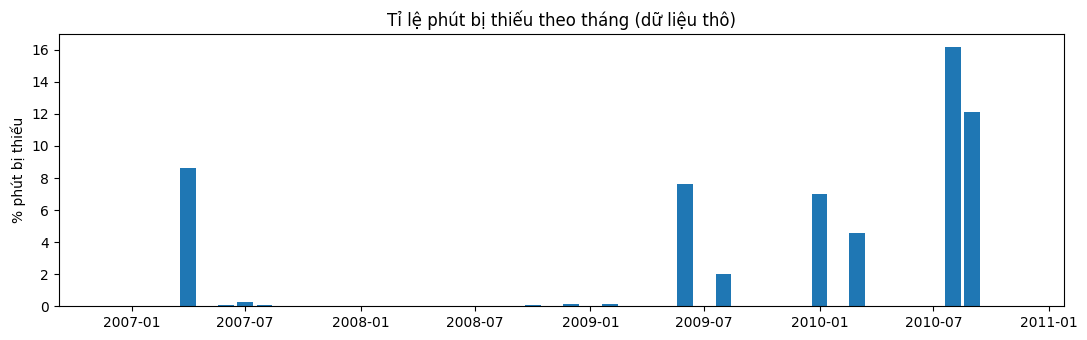

2026-11-14 00:00:36 | INFO | 3 tháng thiếu nhiều nhất: 08/2010 16.2%; 09/2010 12.1%; 04/2007 8.6%


In [5]:
mask = thieu.all(axis=1).to_numpy()
bd, dai = runs(mask)
khoang = pd.DataFrame({"bat_dau": ts.iloc[bd].to_numpy(), "so_phut": dai})
nhom = pd.cut(khoang["so_phut"], [0, 1, 10, 60, 120, np.inf],
              labels=["1 phút", "2–10 phút", "11–60 phút", "61–120 phút", "> 2 giờ"])
bang_khoang = khoang.groupby(nhom, observed=False)["so_phut"].agg(so_khoang="count", tong_phut="sum")
bang_khoang["ti_le_phut_thieu_%"] = (bang_khoang["tong_phut"] / mask.sum() * 100).round(1)
bang_khoang.to_csv(DIR_DATA / "eda_00_do_dai_khoang_thieu.csv", encoding="utf-8-sig")
display(bang_khoang)
log.info(f"{len(khoang)} khoảng thiếu, dài nhất {khoang['so_phut'].max()} phút ({khoang['so_phut'].max() / 60:.1f} giờ, "
         f"bắt đầu {khoang.loc[khoang['so_phut'].idxmax(), 'bat_dau']:%d/%m/%Y %H:%M})")

thieu_thang = pd.Series(mask, index=ts).resample("MS").mean() * 100
thieu_thang.round(3).rename("ti_le_thieu_%").to_csv(DIR_DATA / "eda_00_thieu_theo_thang.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(thieu_thang.index, thieu_thang.values, width=25)
ax.set_ylabel("% phút bị thiếu"); ax.set_title("Tỉ lệ phút bị thiếu theo tháng (dữ liệu thô)")
fig.tight_layout(); fig.savefig(DIR_FIG / "00_thieu_theo_thang.png", dpi=150); plt.show()
top_thang = thieu_thang.sort_values(ascending=False).head(3)
log.info("3 tháng thiếu nhiều nhất: " + "; ".join(f"{d:%m/%Y} {v:.1f}%" for d, v in top_thang.items()))

n_dai = int((khoang["so_phut"] > 120).sum())
ghi_kho_khan("Thiếu thành từng khoảng liền nhau, có khoảng kéo dài nhiều ngày",
             f"{fmt(mask.sum())} phút thiếu ({mask.mean():.2%}) chia thành {len(khoang)} khoảng; {n_dai} khoảng dài hơn 2 giờ, "
             f"dài nhất {khoang['so_phut'].max() / 60:.1f} giờ; thiếu dồn vào vài tháng (cao nhất {top_thang.index[0]:%m/%Y}: {top_thang.iloc[0]:.1f}%)",
             "Không điền nhãn mục tiêu; đầu vào chỉ điền tiến tối đa 2 giờ và có cờ báo thiếu; khoảng dài để NaN",
             "01_cleaning, mục 4 và 8")

**Nhận xét:** 

Có 71 khoảng thiếu. Phần lớn là khoảng ngắn (38 khoảng chỉ 1 phút), nhưng 7 khoảng dài hơn 2 giờ lại chiếm 98,3% tổng số phút thiếu, dài nhất là 120,4 giờ bắt đầu từ 17/08/2010. Vì vậy không nên xử lý mọi khoảng thiếu giống nhau: ở 01_cleaning, khoảng thiếu ngắn (tối đa 2 giờ) được điền tiến cho đầu vào, còn khoảng dài để trống, và nhãn thì không điền.

## Khó khăn dữ liệu rút ra từ E0.2

In [6]:
bang_kk = pd.DataFrame(kho_khan[moc_kk:])
bang_kk.to_csv(DIR_DATA / f"eda_{MA_TN}_kho_khan.csv", encoding="utf-8-sig", index=False)
with pd.option_context("display.max_colwidth", None):
    display(bang_kk)
log.info(f"{MA_TN}: {len(bang_kk)} khó khăn dữ liệu, lưu ở data/eda_data/eda_{MA_TN}_kho_khan.csv")

,Khó khăn,Bằng chứng (số thật),Cách xử lý,Xử lý ở đâu
0,"Thiếu thành từng khoảng liền nhau, có khoảng kéo dài nhiều ngày","25.979 phút thiếu (1.25%) chia thành 71 khoảng; 7 khoảng dài hơn 2 giờ, dài nhất 120.4 giờ; thiếu dồn vào vài tháng (cao nhất 08/2010: 16.2%)",Không điền nhãn mục tiêu; đầu vào chỉ điền tiến tối đa 2 giờ và có cờ báo thiếu; khoảng dài để NaN,"01_cleaning, mục 4 và 8"


2026-11-14 00:00:36 | INFO | E0.2: 1 khó khăn dữ liệu, lưu ở data/eda_E0.2_kho_khan.csv


## Log lên W&B (minh chứng)

In [7]:
# W&B (project cuoi-ky-du-bao-dien-nang). Mặc định TẮT để chạy lại không tạo run trùng.
# Muốn ghi lên W&B: chạy notebook bằng lệnh  BAT_WANDB=1 jupyter nbconvert --to notebook --execute --inplace <notebook>
import os
USE_WANDB = os.environ.get("BAT_WANDB") == "1"
if USE_WANDB:
    import wandb, pandas as pd
    BANG = ['eda_00_do_dai_khoang_thieu.csv', 'eda_00_thieu_theo_thang.csv', 'eda_E0.2_kho_khan.csv']
    HINH = ['00_thieu_theo_thang.png']
    run = wandb.init(entity="sgu-mayhoc-nhom11", project="cuoi-ky-du-bao-dien-nang",
                     name="ck-E0.2-Han-khoang-thieu", tags=["E0.2", "Han", "EDA"],
                     config={"notebook": TEN_NOTEBOOK, "file_log": str(file_log)})
    run.summary.update({"so_khoang_thieu": len(khoang), "khoang_dai_nhat_phut": int(khoang['so_phut'].max()), "so_khoang_tren_2_gio": int((khoang['so_phut'] > 120).sum())})
    run.log({**{"bang/" + b.removesuffix(".csv"): wandb.Table(dataframe=pd.read_csv(DIR_DATA / b)) for b in BANG},
             **{"hinh/" + h.removesuffix(".png"): wandb.Image(str(DIR_FIG / h)) for h in HINH},
             "ket_luan": wandb.Html("<br>".join(str(x) for x in kho_khan[moc_kk:]))})
    log.info(f"Đã ghi W&B: {run.url}")
    run.finish()

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /Users/caongochan/.netrc.


wandb: Currently logged in as: caongochan142 (sgu-mayhoc-nhom11) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run y1l5bvjk


wandb: Tracking run with wandb version 0.31.0


wandb: Run data is saved locally in /Users/caongochan/Documents/Nhom11_DuBaoDienNang_GiuaKy/notebooks/eda/wandb/run-20261114_000037-y1l5bvjk
wandb: Run `wandb offline` to turn off syncing.


wandb: Syncing run ck-E0.2-Han-khoang-thieu


... (11 outputs left out)

wandb: uploading history steps 0-0, summary, console lines 0-0


wandb: 
wandb: Run summary:
wandb: khoang_dai_nhat_phut 7226
wandb:      so_khoang_thieu 71
wandb: so_khoang_tren_2_gio 7
wandb: 


wandb: 🚀 View run ck-E0.2-Han-khoang-thieu at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang/runs/y1l5bvjk
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/sgu-mayhoc-nhom11/cuoi-ky-du-bao-dien-nang
wandb: Synced 5 W&B file(s), 5 media file(s), 6 artifact file(s) and 0 other file(s)


wandb: Find logs at: ./wandb/run-20261114_000037-y1l5bvjk/logs


## Nhật ký

- 13/11/2026 – Viết lần đầu chung trong notebook `00_eda_du_lieu_tho_Han.ipynb` (nay ở `phien_ban_cu/`) rồi tách ra thành notebook riêng `00_E0.2_khoang_thieu_Han.ipynb`, có ô ghi log. Commit `77b73dc`.
- 13/11/2026 – Chạy 3 lần (19:30, 20:10, 20:15). Lần đầu chạy xong nhưng đóng tab chưa lưu nên notebook mất output; lần cuối chạy bằng `jupyter nbconvert` để lưu output. Nội dung 3 file log trùng nhau (chỉ khác giờ chạy), tức là kết quả tái lập được. Commit `5c8d5fd`.
- 13/11/2026 – Chuyển các file log EDA vào `logs/eda_log/` và sửa ô ghi log để các lần chạy sau ghi thẳng vào thư mục này. Commit `44b69dd`.